In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import pickle
import importlib

import model_utils
importlib.reload(model_utils)
from model_utils import *

import tensorflow
import keras

In [2]:
class SkipTFUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        # Intercept Keras/TensorFlow deserialization functions & model objects
        if "keras" in module or "tensorflow" in module or name in ["Functional", "Sequential", "Model"]:
            # Return a dummy placeholder class instead of recreating the Keras object
            return DummyKerasModel
        return super().find_class(module, name)

class DummyKerasModel:
    """Placeholder to safely swallow Keras unpickling calls without crashing."""
    def __init__(self, *args, **kwargs):
        pass
    
    @classmethod
    def _unpickle_model(cls, *args, **kwargs):
        return "<Skipped Keras Model>"

Models Results

In [3]:
n_clients = [10, 15, 20]
iids = ['IID', 'Non-IID']
seeds = [42, 123, 456]
clients = n_clients[2]
iid = iids[1]
seed = seeds[0]

experiment = f'experiments/TON-n_{clients}-{iid}-seed_{seed}.pkl'
with open(experiment, 'rb') as f:
    results = SkipTFUnpickler(f).load()

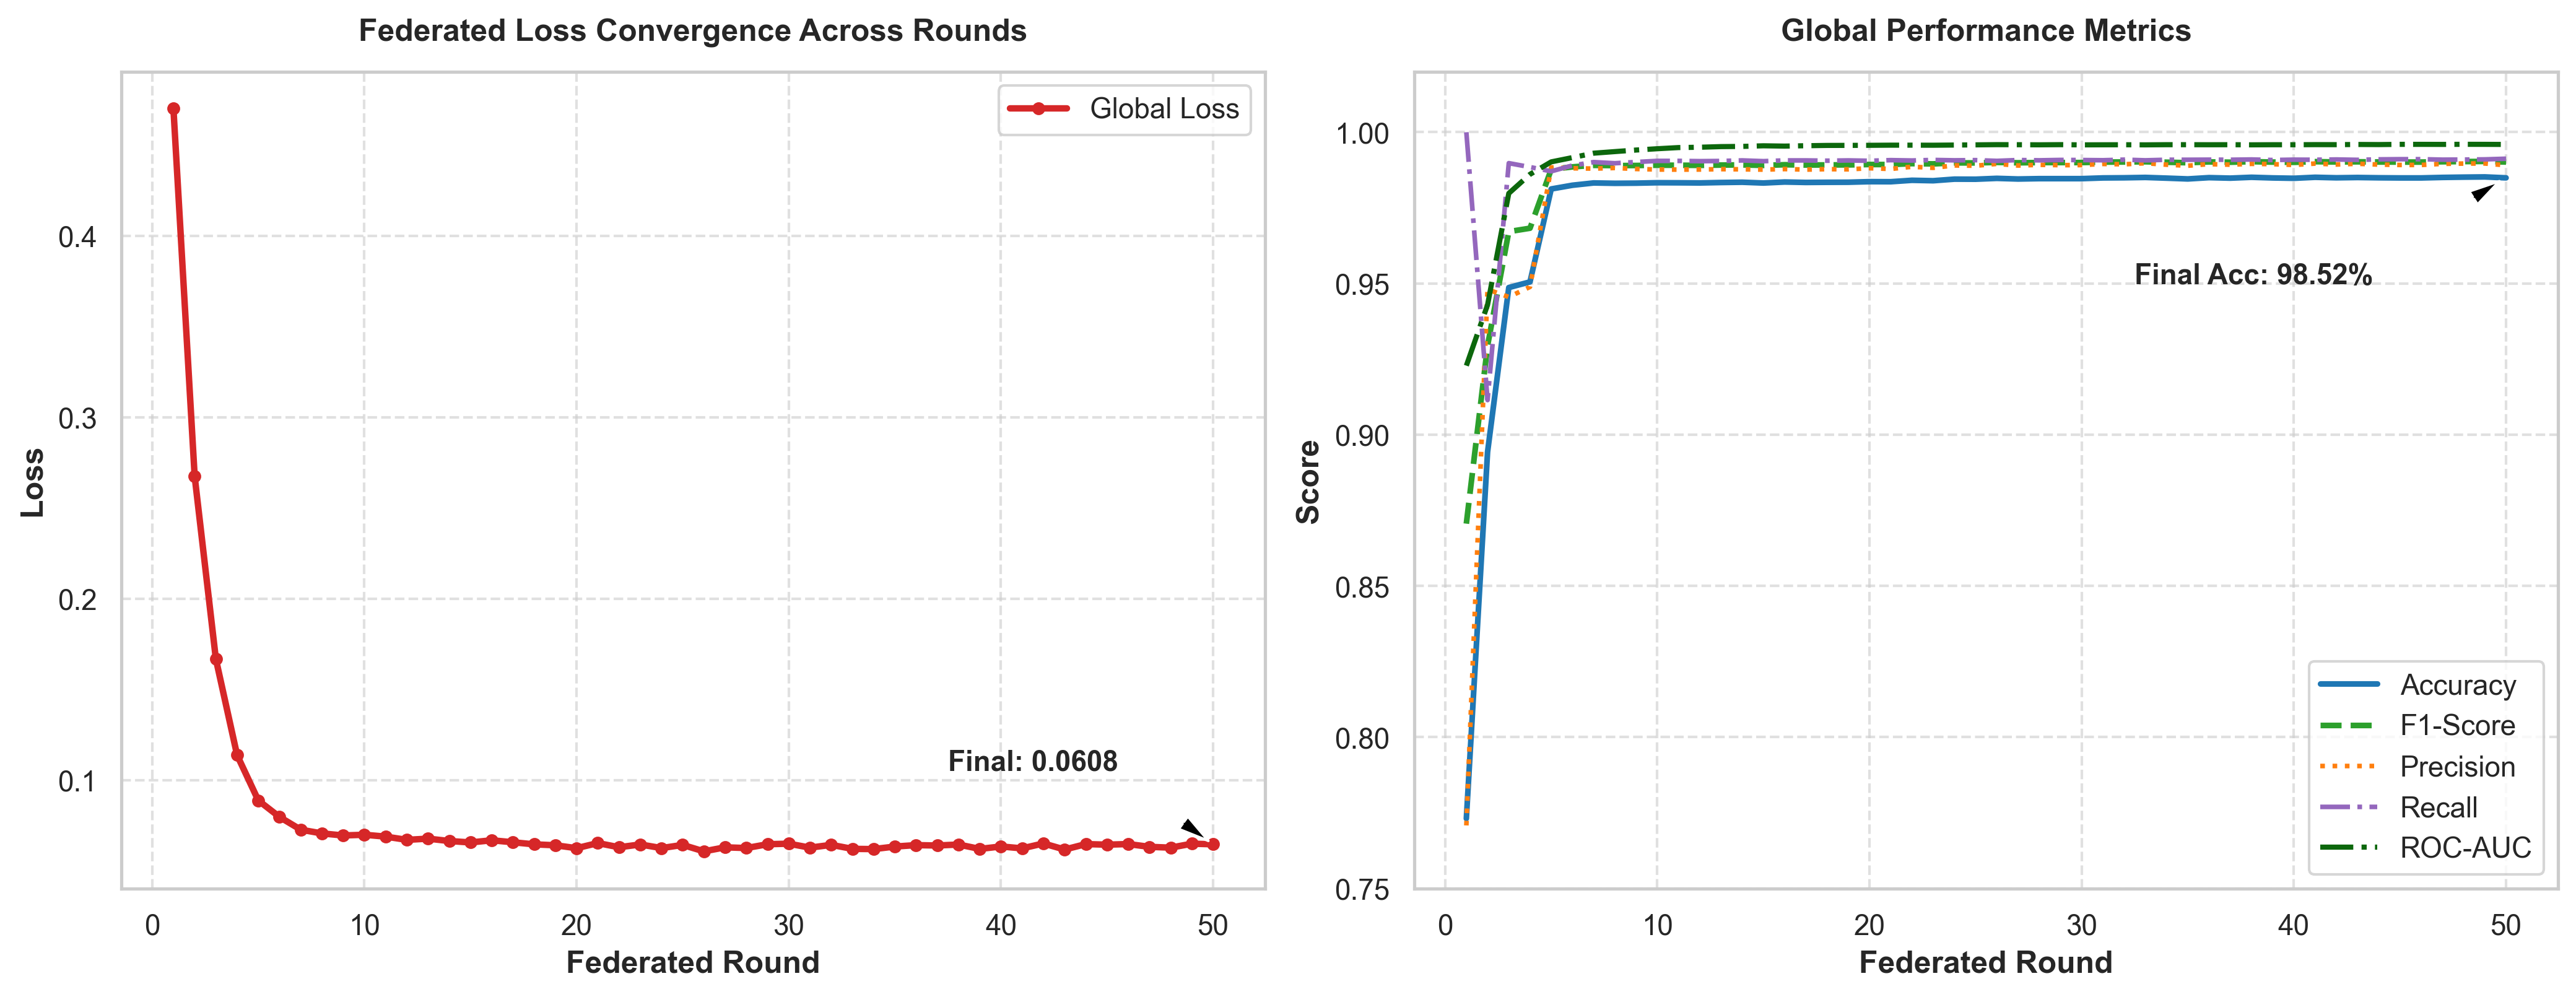

In [30]:

# Set clean scientific plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 11, 'figure.dpi': 300})

def plot_federated_convergence(results, save_fig_path="fl_convergence.png"):
    telemetry = results["telemetry"]

    # Extract round numbers and global metrics
    rounds = []
    losses = []
    accuracies = []
    precisions = []
    recalls = []
    f1s = []
    roc_aucs = []

    # Parse round-level data dynamically
    round_data_source = telemetry["rounds"]


    for entry in round_data_source:
        metrics = entry['global_metrics']
        rounds.append(entry['round'])
        losses.append(metrics["loss"])
        accuracies.append(metrics["accuracy"])
        precisions.append(metrics["precision"])
        recalls.append(metrics["recall"])
        f1s.append(metrics["f1_score"])
        roc_aucs.append(metrics["roc_auc"])

    # Convert to numpy arrays for safety
    rounds = np.array(rounds)
    losses = np.array(losses)
    accuracies = np.array(accuracies)

    # 2. Setup Figure Subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)

    # --- Plot 1: Global Loss Convergence ---
    axes[0].plot(rounds, losses, color="#d62728", lw=2.5, marker="o", ms=4, label="Global Loss")
    axes[0].set_title("Federated Loss Convergence Across Rounds", fontweight="bold", pad=12)
    axes[0].set_xlabel("Federated Round", fontweight="bold")
    axes[0].set_ylabel("Loss", fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend(loc="upper right")

    # Annotate final loss
    if len(losses) > 0:
        axes[0].annotate(
            f"Final: {np.min(losses):.4f}",
            xy=(rounds[-1], losses[-1]),
            xytext=(rounds[-1] - (len(rounds) * 0.25), losses[-1] + (max(losses) - min(losses)) * 0.1),
            arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
            fontweight="bold"
        )

    # --- Plot 2: Global Evaluation Metrics ---
    if len(accuracies) > 0 and not np.isnan(accuracies[0]):
        axes[1].plot(rounds, accuracies, color="#1f77b4", lw=2.2, label="Accuracy")
    if len(f1s) > 0 and not np.isnan(f1s[0]):
        axes[1].plot(rounds, f1s, color="#2ca02c", lw=2.2, linestyle="--", label="F1-Score")
    if len(precisions) > 0 and not np.isnan(precisions[0]):
        axes[1].plot(rounds, precisions, color="#ff7f0e", lw=1.8, linestyle=":", label="Precision")
    if len(recalls) > 0 and not np.isnan(recalls[0]):
        axes[1].plot(rounds, recalls, color="#9467bd", lw=1.8, linestyle="-.", label="Recall")
    
    axes[1].plot(rounds, roc_aucs, color="#0c670c", lw=2, linestyle="-.", label="ROC-AUC")
    
    axes[1].set_title("Global Performance Metrics", fontweight="bold", pad=12)
    axes[1].set_xlabel("Federated Round", fontweight="bold")
    axes[1].set_ylabel("Score", fontweight="bold")
    axes[1].set_ylim(0.75, 1.02)
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend(loc="lower right")

    # Annotate final accuracy
    if len(accuracies) > 0 and not np.isnan(accuracies[-1]):
        axes[1].annotate(
            f"Final Acc: {np.max(accuracies) * 100:.2f}%",
            xy=(rounds[-1], np.max(accuracies)),
            xytext=(rounds[-1] - (len(rounds) * 0.35), 0.95), #np.max(accuracies) - 0.08),
            arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
            fontweight="bold"
        )

    plt.tight_layout()
    plt.savefig(save_fig_path, dpi=300, bbox_inches="tight")
    plt.show()
# Run function on your unpickled results object

plot_federated_convergence(results)


In [39]:
m = results['metrics']
c = results['telemetry']['costs']

print("Summary of Global Autoencoder Performance and Federated Overhead")
print(f"Metric\tValue)")
print(f"Global MSE\t{m.get('Global_MSE', 0):.6f}")
print(f"Global MAE\t{m.get('Global_MAE', 0):.6f}")
print(f"Client Loss Mean\t{m.get('Client_Loss_Mean', 0):.4f} +/- {m.get('Client_Loss_Std', 0):.4f}")
print(f"Silhouette Score\t{m.get('Silhouette_Score', 0):.4f}")
print(f"Correlation Distortion\t{m.get('Correlation_Distortion', 0):.4f}")
print(f"Compression Ratio\t{m.get('Compression_Ratio', 0):.2f}")
print(f"Inference Latency\t{m.get('Throughput_ms_per_sample', 0):.4f} ms/sample")
print(f"Total Parameters\t{c.get('params_count', 0):,}")
print(f"Per-Round Communication\t{c.get('round_comm_mb', 0):.2f} MB")
print(f"Total Communication Overhead\t{c.get('total_comm_mb', 0):.2f} MB")
print(f"Total Training Time\t{c.get('total_training_time_sec', 0):.2f} s")


Summary of Global Autoencoder Performance and Federated Overhead
Metric	Value)
Global MSE	0.000190
Global MAE	0.001041
Client Loss Mean	0.0003 +/- 0.0001
Silhouette Score	0.2729
Correlation Distortion	18.2536
Compression Ratio	50.67
Inference Latency	0.0068 ms/sample
Total Parameters	256,203
Per-Round Communication	39.09 MB
Total Communication Overhead	1954.67 MB
Total Training Time	8423.75 s
